# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Vincent Valentino | 5054251016 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [3]:
mall = pd.read_csv('Mall_Customers.csv')
display(mall.shape)
display(mall.head())

(200, 5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
mall.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [5]:
mall.describe(include='all')

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [6]:
dupes = mall.drop(columns='CustomerID')
print(dupes.duplicated().sum())
mall.isna().sum()

0


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

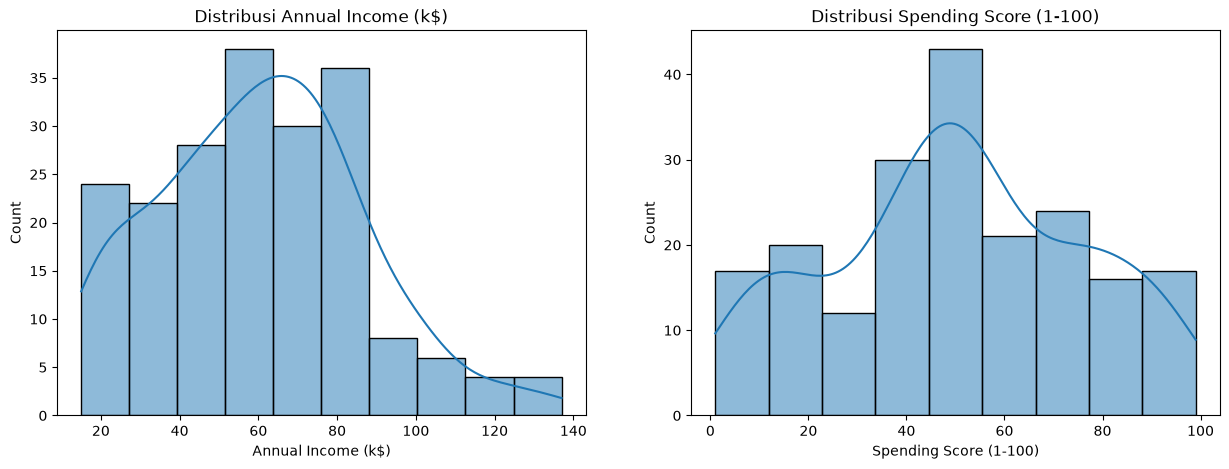

In [7]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
fig, axes = plt.subplots(1,2, figsize=(15,5))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sb.histplot(data=mall, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribusi {col}')

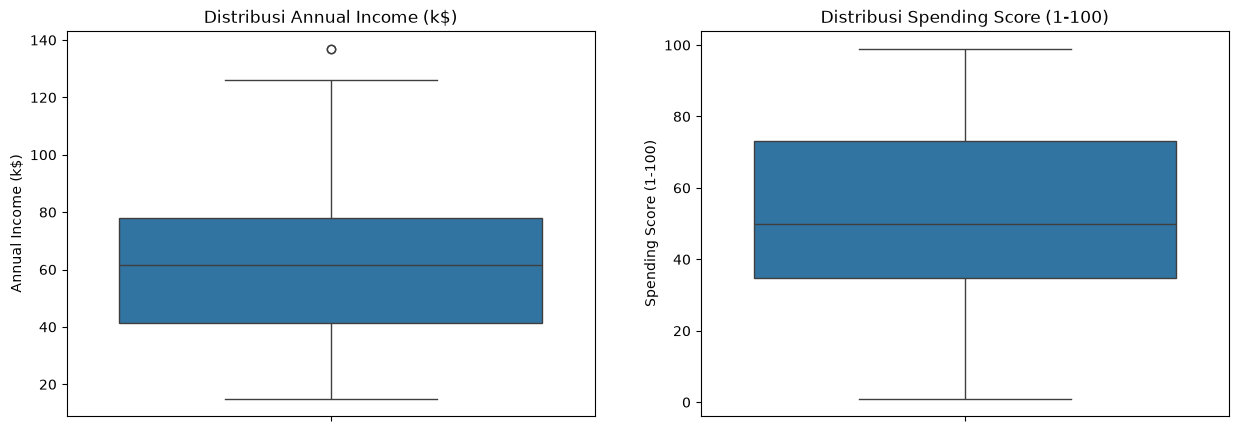

In [8]:
fig, axes = plt.subplots(1,2, figsize=(15,5))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sb.boxplot(data=mall, y=col, ax=ax)
    ax.set_title(f'Distribusi {col}')

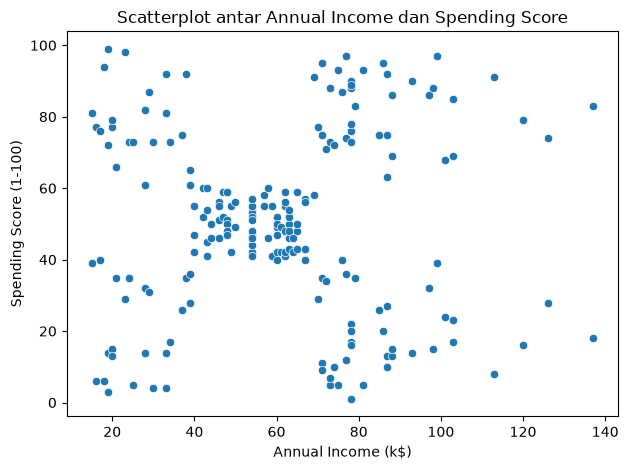

In [9]:
sb.scatterplot(data=mall, x='Annual Income (k$)', y='Spending Score (1-100)')
plt.title('Scatterplot antar Annual Income dan Spending Score')
plt.tight_layout()
plt.show()

## Pertanyaan EDA
**Apakah ada missing value atau baris duplikat?** Tidak ada

**Bagaimana rentang pendapatan dan spending score**

Annual Income berkisar sekitar 15 k$ hingga 137 k$.
* Mayoritas pelanggan berada pada rentang 40–80 k$.
* Terdapat nilai tinggi yang mendekati 140 k$, yang dapat dianggap sebagai outlier.

Spending Score berkisar sekitar 1 hingga 99.
* Sebaran cukup merata dari nilai rendah hingga tinggi.
* Tidak terlihat outlier yang signifikan pada boxplot.

**Apakah kedua fitur tampak memiliki kelompok yang terpisah?**

Ya, terdapat indikasi beberapa kelompok yang cukup jelas pada scatter plot Annual Income vs Spending Score.

Kelompok yang terlihat antara lain:
* Pendapatan rendah, spending tinggi (pojok kanan bawah)
* Pendapatan rendah, spending rendah (pojok kiri bawah)
* Pendapatan tinggi, spending tinggi (pojok kanan atas)
* Pendapatan tinggi, spending rendah (pojok kiri atas)
* Pendapatan dan spending sedang (tengah & yang paling jelas)

# 2. Preprocessing

In [10]:
x = mall[['Annual Income (k$)', 'Spending Score (1-100)']]

In [11]:
scaler = StandardScaler()
x_scaled = pd.DataFrame(scaler.fit_transform(x), columns=x.columns)
display(x_scaled.head())
display(x_scaled.describe())

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


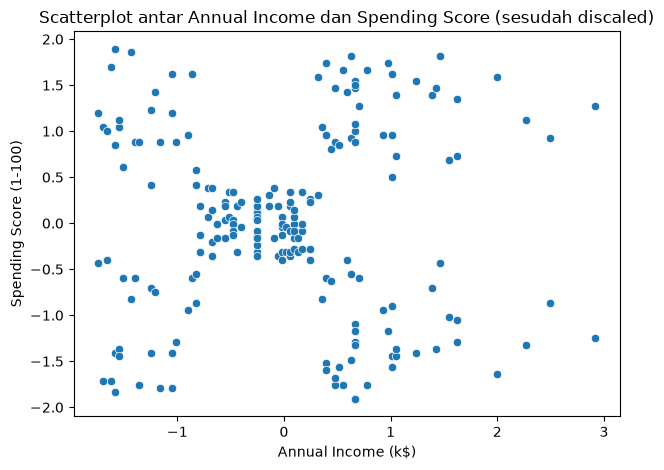

In [12]:
sb.scatterplot(data=x_scaled, x='Annual Income (k$)', y='Spending Score (1-100)')
plt.title('Scatterplot antar Annual Income dan Spending Score (sesudah discaled)')
plt.tight_layout()
plt.show()

Scaling sangat penting dikarenakan algoritma clustering seperti DBSCAN, Birch dan KMeans sangat bergantung terhadap perhitungan jarak. Tanpa scaling, fitur yang memiliki angka yang jauh lebih besar dibanding fitur-fitur lainnya dapat mendominasi pengukuran jarak dan menghasilkan bias

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Kedua fitur dipilih karena secara langsung menggambarkan karakteristik pelanggan yang relevan untuk segmentasi. `Annual Income` (k$) menunjukkan kemampuan finansial pelanggan, sedangkan `Spending Score (1-100)` menunjukkan tingkat pengeluaran atau perilaku konsumsi pelanggan.
`CustomerID` tidak digunakan karena hanya merupakan atribut identitas unik dan tidak berpengaruh sama sekali pada karakteristik pelanggan.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [13]:
db = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = db.fit_predict(x_scaled)

In [14]:
clustered = x.copy()
clustered['cluster'] = labels_dbscan
cluster_size = clustered['cluster'].value_counts().sort_index()
display(cluster_size)

cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

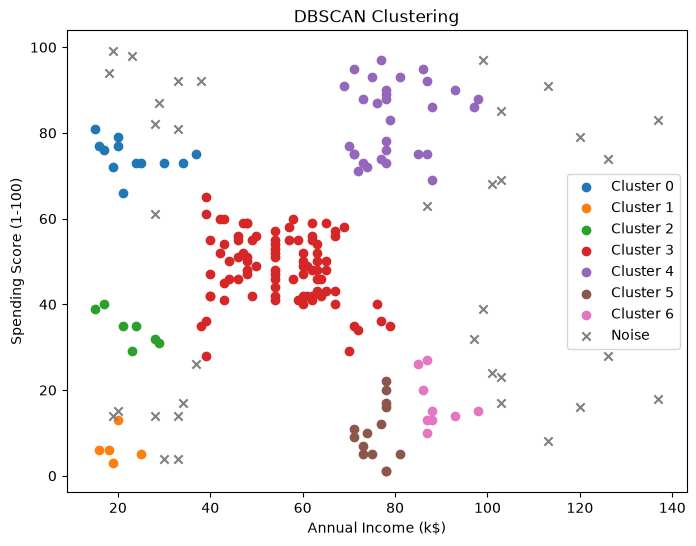

In [33]:
plt.figure(figsize=(8, 6))
for label in set(labels_dbscan):
    mask = labels_dbscan == label
    plt.scatter(x.loc[mask, 'Annual Income (k$)'], x.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}' if label != -1 else 'Noise', marker='x' if label == -1 else 'o')
plt.title('DBSCAN Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [34]:
results = []
for eps in [0.2, 0.3, 0.5, 0.7, 1.0]:
    for min_samples in [3, 5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(x_scaled)
        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)
        score = np.nan
        if n_clusters > 1:
            score = silhouette_score(x_scaled, labels)
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Jumlah Cluster': n_clusters,
            'Jumlah Noise': n_noise,
            'Silhouette Score': score
        })

results_df = pd.DataFrame(results)
display(results_df)

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Silhouette Score
0,0.2,3,13,44,0.230585
1,0.2,5,7,77,0.140579
2,0.2,10,1,129,NaN
3,0.3,3,9,14,0.413619
4,0.3,5,7,35,0.316141
5,0.3,10,4,88,0.140885
6,0.5,3,2,7,0.356602
7,0.5,5,2,8,0.350446
8,0.5,10,4,21,0.406405
9,0.7,3,1,0,NaN


### Analisis DBSCAN

#### 1. Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?

**Terhadap Noise:** Kenaikan `eps` (radius ketetanggaan) secara konsisten menurunkan jumlah noise. Radius pencarian yang semakin lebar membuat titik-titik di area pinggiran atau yang renggang lebih mudah terjangkau oleh core point lain, atau lebih mudah mengumpulkan tetangga untuk menjadi core point sendiri.

**Terhadap Jumlah Cluster:** Pada nilai `eps` yang sangat kecil, sebagian besar data terisolasi menjadi noise sehingga jumlah cluster sedikit/bahkan 0 dan ketika `eps` dinaikkan ke tingkat moderat, titik-titik mulai membentuk kelompok-kelompok terpisah (jumlah cluster bertambah). Namun, jika `eps` terus dinaikkan, cluster-cluster yang sebelumnya terpisah akan mulai saling menyatu (merging/chaining effect).

#### 2. Apa pengaruh `min_samples`?

`min_samples` menentukan jumlah minimum titik dalam radius `eps` agar suatu titik dikategorikan sebagai *core point*.

**Jika `min_samples` diperbesar:**
  - Syarat untuk menjadi *core point* semakin ketat karena membutuhkan lebih banyak tetangga.
  - Jumlah noise cenderung meningkat karena lebih banyak titik gagal memenuhi kriteria kepadatan.

**Jika `min_samples` diperkecil:**
  - Syarat menjadi lebih longgar sehingga lebih banyak titik dapat dikategorikan sebagai *core point*.
  - Jumlah noise cenderung berkurang karena lebih banyak titik dapat bergabung dengan cluster.

#### 3. Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?
- **Menghasilkan satu cluster besar (*under-clustering* / *chaining effect*):** Terjadi ketika nilai `eps` terlalu besar dan `min_samples` relatif kecil hingga sedang. Akibatnya, banyak titik saling terhubung dan membentuk satu cluster besar. Contohnya, `eps = 0.8` dengan `min_samples = 3` atau `5`.

- **Menghasilkan terlalu banyak noise (*over-filtering*):** Terjadi ketika nilai `eps` terlalu kecil dan/atau `min_samples` terlalu besar. Akibatnya, banyak titik tidak memenuhi kriteria kepadatan sehingga dikategorikan sebagai noise. Contohnya, `eps = 0.15` dengan `min_samples = 15` atau `eps = 0.20` dengan `min_samples = 15`.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [35]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(x_scaled)

In [36]:
clustered = x.copy()
clustered['cluster'] = labels_birch
cluster_size = clustered['cluster'].value_counts().sort_index()
display(cluster_size)

cluster
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

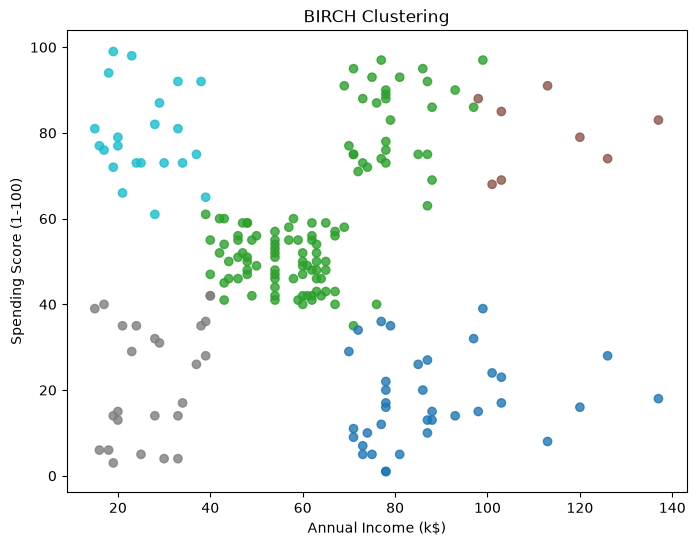

In [37]:
plt.figure(figsize=(8, 6))
plt.scatter(x['Annual Income (k$)'], x['Spending Score (1-100)'], c=labels_birch, cmap='tab10', alpha=0.8)
plt.title('BIRCH Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

In [42]:
results = []

for threshold in [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]:
    model = Birch(threshold=threshold, n_clusters=5)
    labels = model.fit_predict(x_scaled)

    n_clusters = len(set(labels))
    score = np.nan

    if 1 < n_clusters < len(labels):
        score = silhouette_score(x_scaled, labels)

    results.append({
        'Threshold': threshold,
        'Jumlah Cluster': n_clusters,
        'Silhouette Score': score
    })

results_df = pd.DataFrame(results)
display(results_df)

/home/vincent/tugas/.venv/lib/python3.12/site-packages/sklearn/cluster/_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,Threshold,Jumlah Cluster,Silhouette Score
0,0.1,5,0.553809
1,0.2,5,0.553809
2,0.3,5,0.478062
3,0.5,5,0.414450
4,0.7,5,0.420676
5,1.0,4,0.388557


In [20]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

In [21]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [22]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

In [23]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

In [24]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

In [25]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [26]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

In [27]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

In [28]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

In [29]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | | | |
| Dapat memberi label noise secara eksplisit? | | | |
| Parameter yang paling memengaruhi hasil | | | |
| Bentuk cluster yang dapat dimodelkan | | | |
| Kelebihan | | | |
| Kekurangan | | | |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)